Image loaded successfully
Original shape: (512, 512, 3)


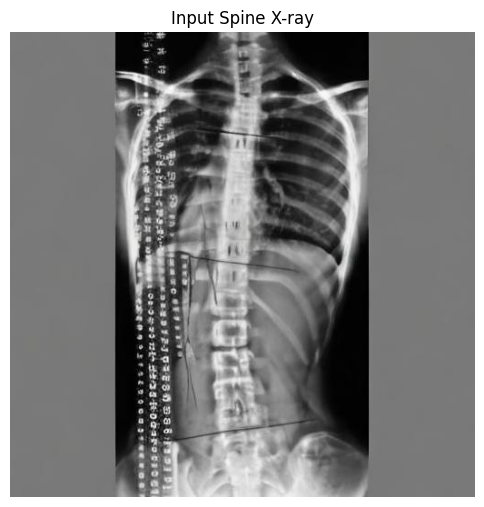

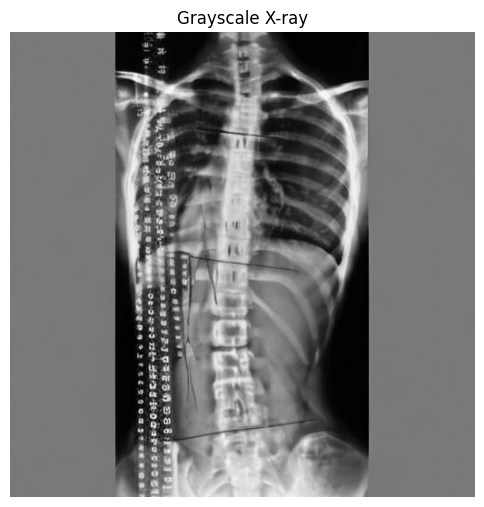

In [ ]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

test_image_path = train_images[0]

image = cv2.imread(test_image_path)

if image is None:
    print("Image not loaded")
else:
    print("Image loaded successfully")
    print("Original shape:", image.shape)

image_rgb = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)


gray = cv2.cvtColor(image_rgb, cv2.COLOR_RGB2GRAY)


plt.figure(figsize=(6, 8))
plt.imshow(image_rgb)
plt.title("Input Spine X-ray")
plt.axis("off")
plt.show()

plt.figure(figsize=(6, 8))
plt.imshow(gray, cmap="gray")
plt.title("Grayscale X-ray")
plt.axis("off")
plt.show()

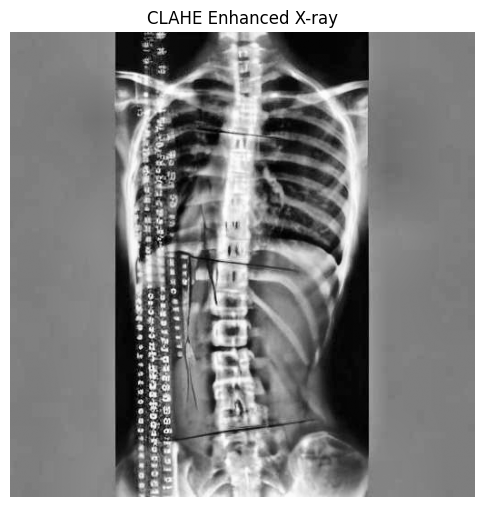

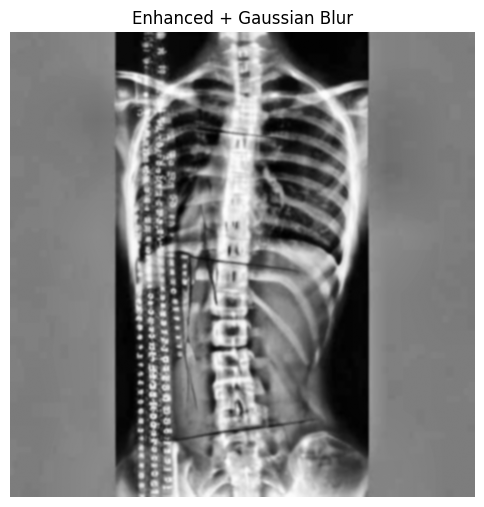

In [ ]:

clahe = cv2.createCLAHE(
    clipLimit=2.0,
    tileGridSize=(8, 8)
)

enhanced = clahe.apply(gray)

blur = cv2.GaussianBlur(enhanced, (5, 5), 0)

plt.figure(figsize=(6, 8))
plt.imshow(enhanced, cmap="gray")
plt.title("CLAHE Enhanced X-ray")
plt.axis("off")
plt.show()

plt.figure(figsize=(6, 8))
plt.imshow(blur, cmap="gray")
plt.title("Enhanced + Gaussian Blur")
plt.axis("off")
plt.show()

Image size: 512 x 512


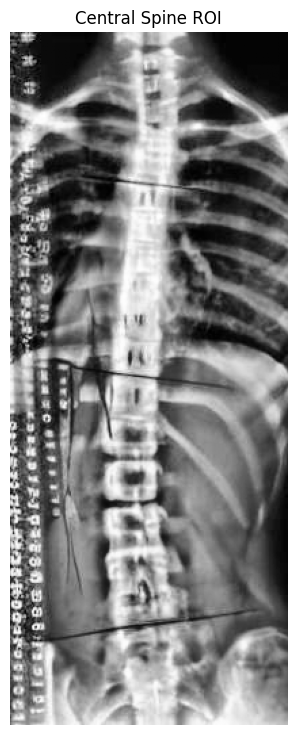

ROI shape: (512, 205)


In [ ]:

h, w = enhanced.shape

print("Image size:", w, "x", h)

x_start = int(w * 0.30)
x_end   = int(w * 0.70)

spine_roi = enhanced[:, x_start:x_end]

plt.figure(figsize=(5, 9))
plt.imshow(spine_roi, cmap="gray")
plt.title("Central Spine ROI")
plt.axis("off")
plt.show()

print("ROI shape:", spine_roi.shape)

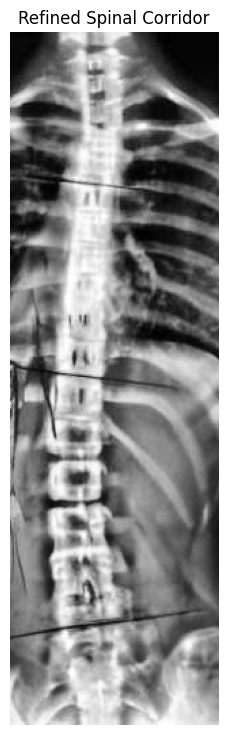

Refined ROI shape: (512, 154)


In [ ]:


h, w = enhanced.shape

x_start = int(w * 0.38)
x_end   = int(w * 0.68)

spine_roi = enhanced[:, x_start:x_end]

plt.figure(figsize=(5, 9))
plt.imshow(spine_roi, cmap="gray")
plt.title("Refined Spinal Corridor")
plt.axis("off")
plt.show()

print("Refined ROI shape:", spine_roi.shape)

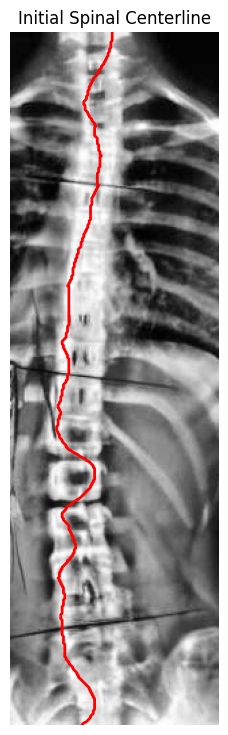

Centerline points: 512


In [ ]:


roi_gray = spine_roi.copy()

h, w = roi_gray.shape

centerline = []

x_prev = w // 2

window = 20

for y in range(h):

    row = roi_gray[y]

    left = max(0, x_prev - window)
    right = min(w, x_prev + window + 1)

    segment = row[left:right]

    if len(segment) > 0:
        x_local = np.argmax(segment)
        x = left + x_local
    else:
        x = x_prev

    centerline.append([x, y])

    x_prev = x

centerline = np.array(centerline)

from scipy.signal import savgol_filter

centerline[:, 0] = savgol_filter(
    centerline[:, 0],
    51,
    3
)

plt.figure(figsize=(5, 9))
plt.imshow(roi_gray, cmap="gray")
plt.plot(
    centerline[:, 0],
    centerline[:, 1],
    color="red",
    linewidth=2
)
plt.title("Initial Spinal Centerline")
plt.axis("off")
plt.show()

print("Centerline points:", len(centerline))

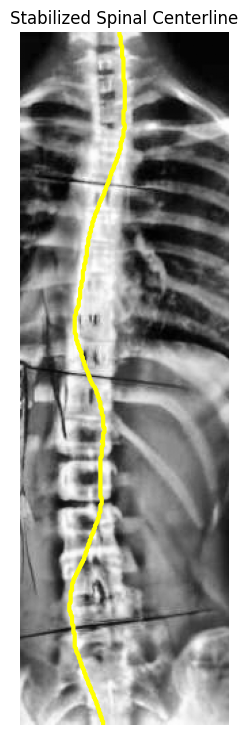

Centerline points: 512


In [ ]:

roi_smooth = cv2.GaussianBlur(
    roi_gray,
    (7, 7),
    0
)

h, w = roi_smooth.shape

centerline_stable = []


x_prev = w // 2

window = 12

for y in range(h):

    row = roi_smooth[y]

    left = max(0, x_prev - window)
    right = min(w, x_prev + window + 1)

    segment = row[left:right]

    if len(segment) > 0:
        x_local = np.argmax(segment)
        x = left + x_local
    else:
        x = x_prev

    centerline_stable.append([x, y])

    x_prev = x

centerline_stable = np.array(centerline_stable)

centerline_stable[:, 0] = savgol_filter(
    centerline_stable[:, 0],
    101,
    3
)

plt.figure(figsize=(5, 9))
plt.imshow(roi_gray, cmap="gray")

plt.plot(
    centerline_stable[:, 0],
    centerline_stable[:, 1],
    color="yellow",
    linewidth=3
)

plt.title("Stabilized Spinal Centerline")
plt.axis("off")
plt.show()

print("Centerline points:", len(centerline_stable))

Apex index: 302
Apex position: [ 60 302]


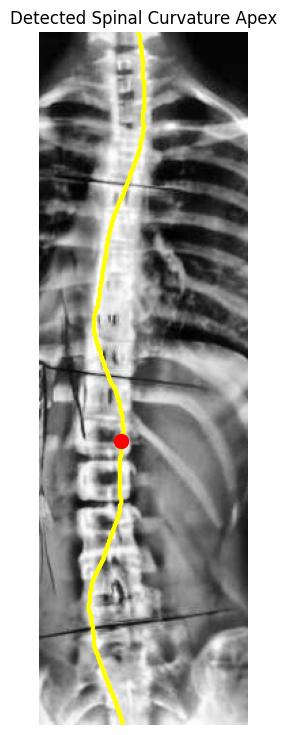

In [ ]:


x = centerline_stable[:, 0]
y = centerline_stable[:, 1]


dx = np.gradient(x)
d2x = np.gradient(dx)


curvature = np.abs(d2x)


h = len(centerline_stable)

start = int(0.15 * h)
end = int(0.85 * h)

apex_index = start + np.argmax(curvature[start:end])

apex = centerline_stable[apex_index]

print("Apex index:", apex_index)
print("Apex position:", apex)

plt.figure(figsize=(5, 9))
plt.imshow(roi_gray, cmap="gray")

plt.plot(
    centerline_stable[:, 0],
    centerline_stable[:, 1],
    color="yellow",
    linewidth=3
)

plt.scatter(
    apex[0],
    apex[1],
    color="red",
    s=100,
    zorder=5
)

plt.title("Detected Spinal Curvature Apex")
plt.axis("off")
plt.show()

In [ ]:

upper = centerline_stable[:apex_index]
lower = centerline_stable[apex_index:]


upper_part = upper[int(len(upper) * 0.35):]
lower_part = lower[:int(len(lower) * 0.65)]


m1, c1 = np.polyfit(
    upper_part[:, 1],
    upper_part[:, 0],
    1
)

m2, c2 = np.polyfit(
    lower_part[:, 1],
    lower_part[:, 0],
    1
)


theta = abs(
    np.arctan(m1) - np.arctan(m2)
)

curvature_angle = np.degrees(theta)

print(f"Centerline Curvature Angle: {curvature_angle:.2f}°")

Centerline Curvature Angle: 12.23°


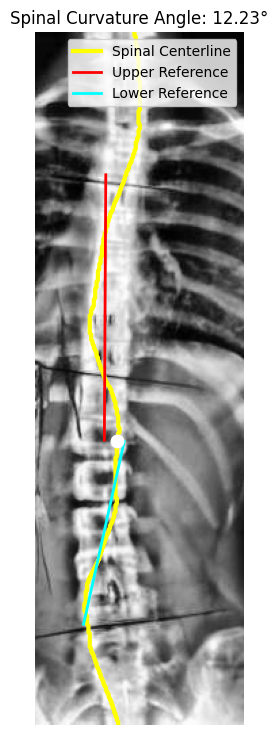

In [ ]:


plt.figure(figsize=(5, 9))
plt.imshow(roi_gray, cmap="gray")


plt.plot(
    centerline_stable[:, 0],
    centerline_stable[:, 1],
    color="yellow",
    linewidth=3,
    label="Spinal Centerline"
)


y_upper = np.linspace(
    upper_part[:, 1].min(),
    upper_part[:, 1].max(),
    100
)

x_upper = m1 * y_upper + c1

plt.plot(
    x_upper,
    y_upper,
    color="red",
    linewidth=2,
    label="Upper Reference"
)

y_lower = np.linspace(
    lower_part[:, 1].min(),
    lower_part[:, 1].max(),
    100
)

x_lower = m2 * y_lower + c2

plt.plot(
    x_lower,
    y_lower,
    color="cyan",
    linewidth=2,
    label="Lower Reference"
)


plt.scatter(
    apex[0],
    apex[1],
    color="white",
    s=80,
    zorder=5
)

plt.title(
    f"Spinal Curvature Angle: {curvature_angle:.2f}°"
)

plt.legend()
plt.axis("off")
plt.show()

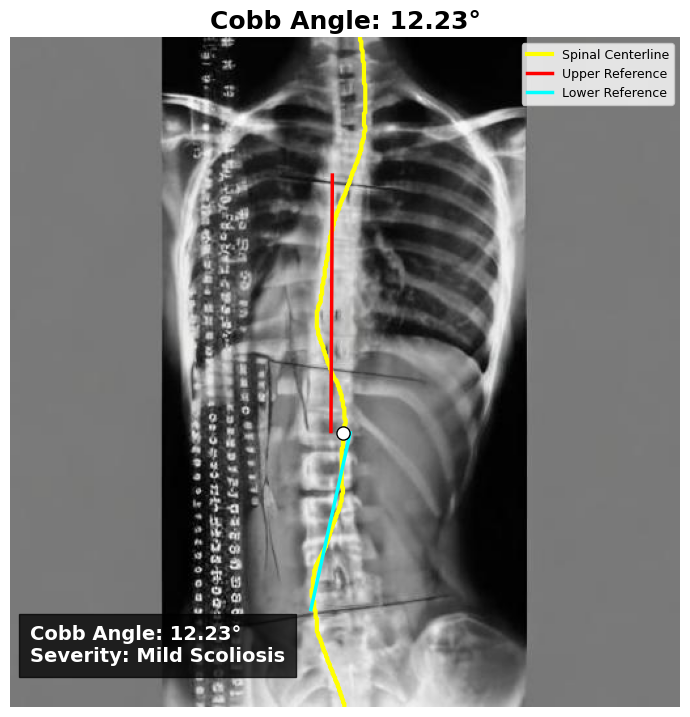

Cobb Angle : 12.23°
Severity   : Mild Scoliosis


In [ ]:

centerline_full = centerline_stable.copy()
centerline_full[:, 0] += x_start

upper_x_full = x_upper + x_start
lower_x_full = x_lower + x_start


if curvature_angle < 10:
    severity = "Normal"
elif curvature_angle < 25:
    severity = "Mild Scoliosis"
elif curvature_angle < 40:
    severity = "Moderate Scoliosis"
else:
    severity = "Severe Scoliosis"


plt.figure(figsize=(7, 10))
plt.imshow(image_rgb)

plt.plot(
    centerline_full[:, 0],
    centerline_full[:, 1],
    color="yellow",
    linewidth=3,
    label="Spinal Centerline"
)


plt.plot(
    upper_x_full,
    y_upper,
    color="red",
    linewidth=2.5,
    label="Upper Reference"
)


plt.plot(
    lower_x_full,
    y_lower,
    color="cyan",
    linewidth=2.5,
    label="Lower Reference"
)


plt.scatter(
    apex[0] + x_start,
    apex[1],
    color="white",
    edgecolors="black",
    s=90,
    zorder=5
)


plt.title(
    f"Cobb Angle: {curvature_angle:.2f}°",
    fontsize=18,
    fontweight="bold"
)


plt.text(
    15,
    image_rgb.shape[0] - 35,
    f"Cobb Angle: {curvature_angle:.2f}°\n"
    f"Severity: {severity}",
    color="white",
    fontsize=14,
    fontweight="bold",
    bbox=dict(
        facecolor="black",
        alpha=0.75,
        pad=8
    )
)

plt.legend(
    loc="upper right",
    fontsize=9
)

plt.axis("off")
plt.tight_layout()
plt.show()

print("=" * 40)
print(f"Cobb Angle : {curvature_angle:.2f}°")
print(f"Severity   : {severity}")
print("=" * 40)

In [ ]:
from scipy.signal import savgol_filter
import cv2
import numpy as np

def calculate_cobb_angle(image_path):


    image = cv2.imread(image_path)

    if image is None:
        return None

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)

    h, w = enhanced.shape

    x_start = int(w * 0.38)
    x_end = int(w * 0.68)

    spine_roi = enhanced[:, x_start:x_end]

    roi_smooth = cv2.GaussianBlur(
        spine_roi,
        (7, 7),
        0
    )

    h_roi, w_roi = roi_smooth.shape


    centerline = []

    x_prev = w_roi // 2
    window = 12

    for y in range(h_roi):

        row = roi_smooth[y]

        left = max(0, x_prev - window)
        right = min(w_roi, x_prev + window + 1)

        segment = row[left:right]

        if len(segment) > 0:
            x_local = np.argmax(segment)
            x = left + x_local
        else:
            x = x_prev

        centerline.append([x, y])
        x_prev = x

    centerline = np.array(centerline)

    if len(centerline) >= 101:
        centerline[:, 0] = savgol_filter(
            centerline[:, 0],
            101,
            3
        )


    x = centerline[:, 0]

    dx = np.gradient(x)
    d2x = np.gradient(dx)

    curvature = np.abs(d2x)

    start = int(0.15 * len(centerline))
    end = int(0.85 * len(centerline))

    apex_index = start + np.argmax(
        curvature[start:end]
    )

    upper = centerline[:apex_index]
    lower = centerline[apex_index:]

    if len(upper) < 10 or len(lower) < 10:
        return None

    upper_part = upper[int(len(upper) * 0.35):]
    lower_part = lower[:int(len(lower) * 0.65)]

    m1, c1 = np.polyfit(
        upper_part[:, 1],
        upper_part[:, 0],
        1
    )

    m2, c2 = np.polyfit(
        lower_part[:, 1],
        lower_part[:, 0],
        1
    )


    theta = abs(
        np.arctan(m1) - np.arctan(m2)
    )

    cobb_angle = np.degrees(theta)

    return cobb_angle



test_paths = train_images[:10]

print("=" * 50)
print("MULTI-IMAGE COBB ANGLE TEST")
print("=" * 50)

results = []

for i, path in enumerate(test_paths):

    angle = calculate_cobb_angle(path)

    results.append(angle)

    filename = path.split("/")[-1]

    if angle is not None:
        print(f"{i+1:02d}. {filename[:35]:35s} → Cobb Angle: {angle:.2f}°")
    else:
        print(f"{i+1:02d}. {filename[:35]:35s} → Failed")

print("=" * 50)

valid_results = [
    x for x in results
    if x is not None
]

print("Successful:", len(valid_results), "/ 10")

if valid_results:
    print(
        f"Mean Cobb Angle: "
        f"{np.mean(valid_results):.2f}°"
    )

    print(
        f"Minimum: "
        f"{np.min(valid_results):.2f}°"
    )

    print(
        f"Maximum: "
        f"{np.max(valid_results):.2f}°"
    )

MULTI-IMAGE COBB ANGLE TEST
01. 000030.jpg                          → Cobb Angle: 12.23°
02. 000536.jpg                          → Cobb Angle: 15.70°
03. 000696.jpg                          → Cobb Angle: 8.34°
04. 000558.jpg                          → Cobb Angle: 3.72°
05. 000837.jpg                          → Cobb Angle: 37.80°
06. 000597.jpg                          → Cobb Angle: 24.24°
07. 000166.jpg                          → Cobb Angle: 8.52°
08. 000919.jpg                          → Cobb Angle: 20.84°
09. 000496.jpg                          → Cobb Angle: 13.99°
10. 000825.jpg                          → Cobb Angle: 11.11°
Successful: 10 / 10
Mean Cobb Angle: 15.65°
Minimum: 3.72°
Maximum: 37.80°


In [ ]:


print("=" * 75)
print("PREDICTED vs GROUND-TRUTH COBB ANGLES")
print("=" * 75)

for i in range(10):

    predicted = results[i]


    ground_truth = train_angles[i]

    print(f"\nImage {i+1:02d}")
    print(f"Predicted Cobb Angle : {predicted:.2f}°")
    print(
        f"Ground Truth Angles  : "
        f"{ground_truth[0]:.2f}°, "
        f"{ground_truth[1]:.2f}°, "
        f"{ground_truth[2]:.2f}°"
    )

print("\n" + "=" * 75)

PREDICTED vs GROUND-TRUTH COBB ANGLES

Image 01
Predicted Cobb Angle : 12.23°
Ground Truth Angles  : 0.00°, 8.13°, 14.18°

Image 02
Predicted Cobb Angle : 15.70°
Ground Truth Angles  : 10.68°, 18.36°, 18.80°

Image 03
Predicted Cobb Angle : 8.34°
Ground Truth Angles  : 11.22°, 25.58°, 7.72°

Image 04
Predicted Cobb Angle : 3.72°
Ground Truth Angles  : 13.33°, 32.72°, 24.12°

Image 05
Predicted Cobb Angle : 37.80°
Ground Truth Angles  : 10.58°, 21.59°, 18.37°

Image 06
Predicted Cobb Angle : 24.24°
Ground Truth Angles  : 9.20°, 24.19°, 18.58°

Image 07
Predicted Cobb Angle : 8.52°
Ground Truth Angles  : 4.44°, 9.45°, 3.50°

Image 08
Predicted Cobb Angle : 20.84°
Ground Truth Angles  : 7.91°, 10.57°, 9.46°

Image 09
Predicted Cobb Angle : 13.99°
Ground Truth Angles  : 0.00°, 10.01°, 15.36°

Image 10
Predicted Cobb Angle : 11.11°
Ground Truth Angles  : 21.92°, 30.58°, 27.19°



In [ ]:


print("=" * 65)
print("GROUND-TRUTH COBB ANGLES — FIRST 10 IMAGES")
print("=" * 65)

for i in range(10):
    angles = train_angles[i]

    print(
        f"Image {i+1:02d} | "
        f"Angle 1: {angles[0]:6.2f}° | "
        f"Angle 2: {angles[1]:6.2f}° | "
        f"Angle 3: {angles[2]:6.2f}°"
    )

GROUND-TRUTH COBB ANGLES — FIRST 10 IMAGES
Image 01 | Angle 1:   0.00° | Angle 2:   8.13° | Angle 3:  14.18°
Image 02 | Angle 1:  10.68° | Angle 2:  18.36° | Angle 3:  18.80°
Image 03 | Angle 1:  11.22° | Angle 2:  25.58° | Angle 3:   7.72°
Image 04 | Angle 1:  13.33° | Angle 2:  32.72° | Angle 3:  24.12°
Image 05 | Angle 1:  10.58° | Angle 2:  21.59° | Angle 3:  18.37°
Image 06 | Angle 1:   9.20° | Angle 2:  24.19° | Angle 3:  18.58°
Image 07 | Angle 1:   4.44° | Angle 2:   9.45° | Angle 3:   3.50°
Image 08 | Angle 1:   7.91° | Angle 2:  10.57° | Angle 3:   9.46°
Image 09 | Angle 1:   0.00° | Angle 2:  10.01° | Angle 3:  15.36°
Image 10 | Angle 1:  21.92° | Angle 2:  30.58° | Angle 3:  27.19°


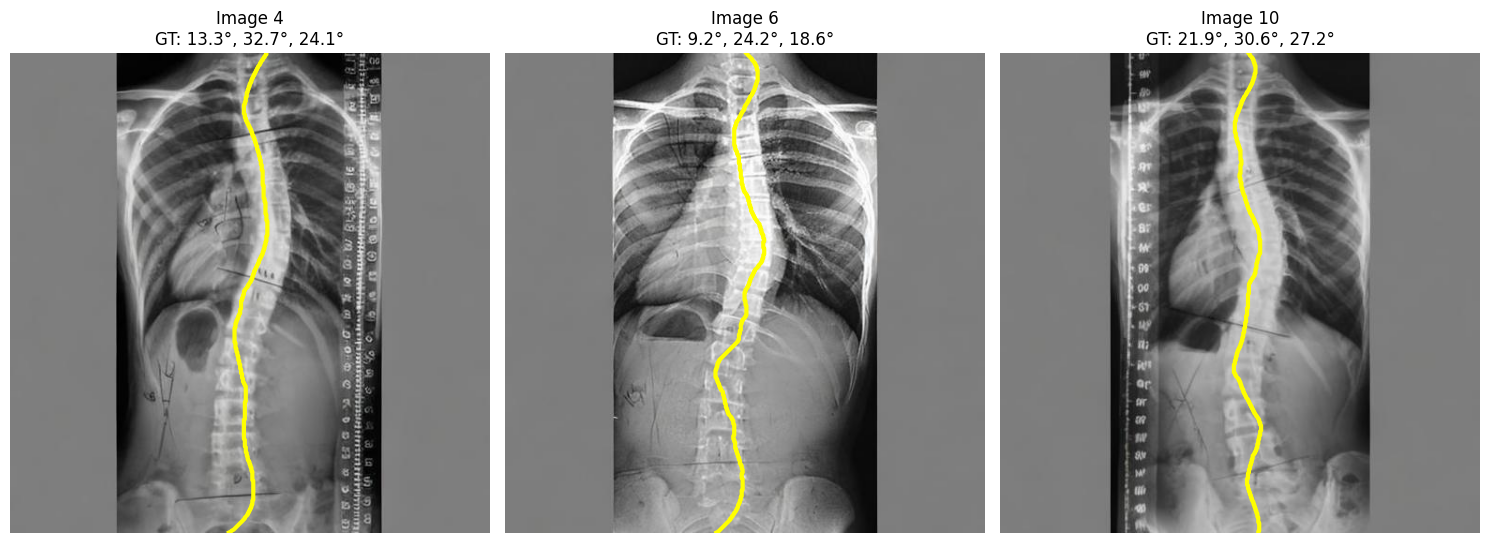

In [ ]:


def get_centerline(image_path):

    image = cv2.imread(image_path)

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)


    h, w = enhanced.shape

    x_start = int(w * 0.38)
    x_end = int(w * 0.68)

    spine_roi = enhanced[:, x_start:x_end]


    roi_smooth = cv2.GaussianBlur(
        spine_roi,
        (7, 7),
        0
    )

    h_roi, w_roi = roi_smooth.shape

    centerline = []

    x_prev = w_roi // 2
    window = 12

    for y in range(h_roi):

        row = roi_smooth[y]

        left = max(0, x_prev - window)
        right = min(w_roi, x_prev + window + 1)

        segment = row[left:right]

        if len(segment) > 0:
            x_local = np.argmax(segment)
            x = left + x_local
        else:
            x = x_prev

        centerline.append([x, y])
        x_prev = x

    centerline = np.array(centerline)


    centerline[:, 0] = savgol_filter(
        centerline[:, 0],
        101,
        3
    )

    return enhanced, centerline, x_start


indices = [3, 5, 9]

plt.figure(figsize=(15, 8))

for plot_idx, idx in enumerate(indices):

    enhanced_img, centerline, x_start_img = get_centerline(
        train_images[idx]
    )


    centerline_full = centerline.copy()
    centerline_full[:, 0] += x_start_img

    image = cv2.imread(train_images[idx])
    image_rgb_temp = cv2.cvtColor(
        image,
        cv2.COLOR_BGR2RGB
    )

    ax = plt.subplot(1, 3, plot_idx + 1)

    ax.imshow(image_rgb_temp)

    ax.plot(
        centerline_full[:, 0],
        centerline_full[:, 1],
        color="yellow",
        linewidth=3
    )

    angles = train_angles[idx]

    ax.set_title(
        f"Image {idx+1}\n"
        f"GT: {angles[0]:.1f}°, "
        f"{angles[1]:.1f}°, "
        f"{angles[2]:.1f}°"
    )

    ax.axis("off")

plt.tight_layout()
plt.show()

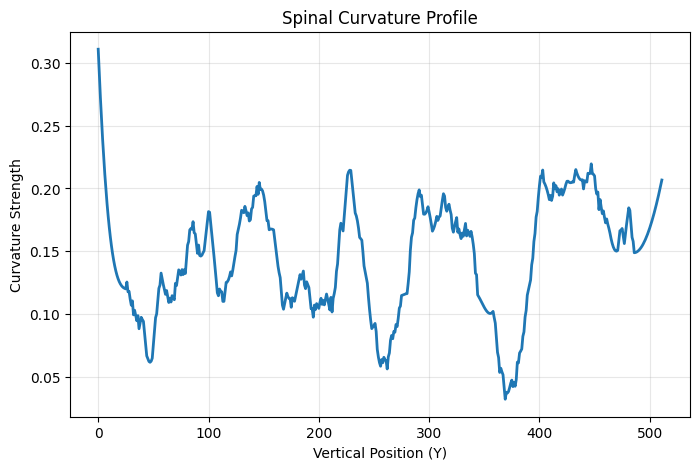

Curvature profile generated.
Number of centerline points: 512


In [ ]:


x = centerline[:, 0]
y = centerline[:, 1]

dx = np.gradient(x)


d2x = np.gradient(dx)


curvature = np.abs(d2x)

curvature_smooth = savgol_filter(
    curvature,
    51,
    3
)

plt.figure(figsize=(8, 5))

plt.plot(
    y,
    curvature_smooth,
    linewidth=2
)

plt.xlabel("Vertical Position (Y)")
plt.ylabel("Curvature Strength")
plt.title("Spinal Curvature Profile")

plt.grid(alpha=0.3)
plt.show()

print("Curvature profile generated.")
print("Number of centerline points:", len(x))

Detected curvature peaks: 4
Peak positions: [146 228 313 447]


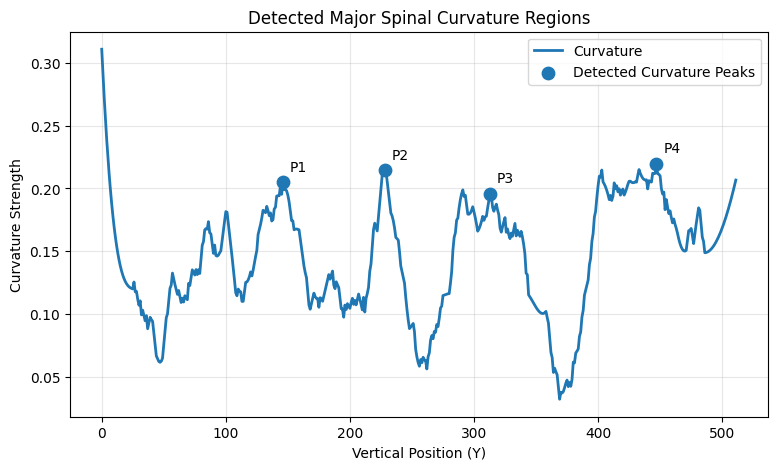

In [ ]:
from scipy.signal import find_peaks

peaks, properties = find_peaks(
    curvature_smooth,
    distance=80,
    prominence=0.025
)

print("Detected curvature peaks:", len(peaks))
print("Peak positions:", peaks)

plt.figure(figsize=(9, 5))

plt.plot(
    y,
    curvature_smooth,
    linewidth=2,
    label="Curvature"
)

plt.scatter(
    y[peaks],
    curvature_smooth[peaks],
    s=80,
    zorder=5,
    label="Detected Curvature Peaks"
)

for i, peak in enumerate(peaks):
    plt.annotate(
        f"P{i+1}",
        (y[peak], curvature_smooth[peak]),
        xytext=(5, 8),
        textcoords="offset points"
    )

plt.xlabel("Vertical Position (Y)")
plt.ylabel("Curvature Strength")
plt.title("Detected Major Spinal Curvature Regions")
plt.grid(alpha=0.3)
plt.legend()
plt.show()

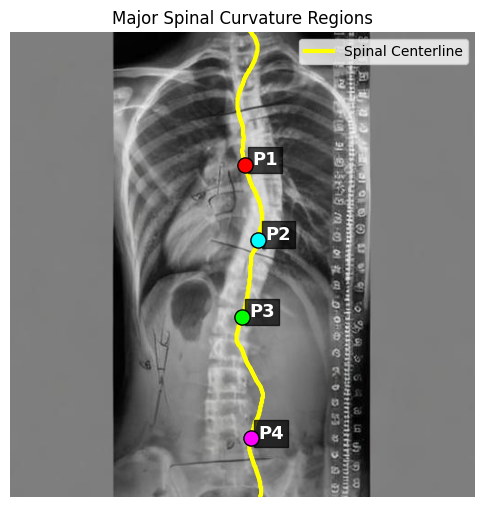

In [ ]:


image = cv2.imread(train_images[3])
image_rgb_temp = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)

centerline_full = centerline.copy()
centerline_full[:, 0] += x_start

plt.figure(figsize=(6, 10))

plt.imshow(image_rgb_temp)

plt.plot(
    centerline_full[:, 0],
    centerline_full[:, 1],
    color="yellow",
    linewidth=3,
    label="Spinal Centerline"
)

colors = ["red", "cyan", "lime", "magenta"]

for i, peak in enumerate(peaks):

    x_peak = centerline_full[peak, 0]
    y_peak = centerline_full[peak, 1]

    plt.scatter(
        x_peak,
        y_peak,
        color=colors[i % len(colors)],
        edgecolors="black",
        s=120,
        zorder=5
    )

    plt.text(
        x_peak + 8,
        y_peak,
        f"P{i+1}",
        color="white",
        fontsize=13,
        fontweight="bold",
        bbox=dict(
            facecolor="black",
            alpha=0.7,
            pad=3
        )
    )

plt.title("Major Spinal Curvature Regions")
plt.axis("off")
plt.legend()
plt.show()

In [ ]:


local_angles = []

for i, peak in enumerate(peaks):

    window_size = 60

    start_idx = max(0, peak - window_size)
    end_idx = min(len(centerline) - 1, peak + window_size)

    local_upper = centerline[start_idx:peak]
    local_lower = centerline[peak:end_idx]

    if len(local_upper) < 10 or len(local_lower) < 10:
        local_angles.append(None)
        continue


    upper_part = local_upper[:int(len(local_upper) * 0.65)]
    lower_part = local_lower[int(len(local_lower) * 0.35):]

    m1, c1 = np.polyfit(
        upper_part[:, 1],
        upper_part[:, 0],
        1
    )

    m2, c2 = np.polyfit(
        lower_part[:, 1],
        lower_part[:, 0],
        1
    )


    theta = abs(
        np.arctan(m1) - np.arctan(m2)
    )

    angle = np.degrees(theta)


    if angle > 90:
        angle = 180 - angle

    local_angles.append(angle)

print("=" * 50)
print("LOCAL COBB ANGLES")
print("=" * 50)

for i, angle in enumerate(local_angles):

    if angle is not None:
        print(
            f"P{i+1} → Cobb Angle: {angle:.2f}°"
        )
    else:
        print(
            f"P{i+1} → Could not calculate"
        )

LOCAL COBB ANGLES
P1 → Cobb Angle: 9.13°
P2 → Cobb Angle: 22.34°
P3 → Cobb Angle: 30.26°
P4 → Cobb Angle: 21.12°


In [ ]:
# Inspect the importance of each detected curvature peak

print("=" * 55)
print("CURVATURE PEAK ANALYSIS")
print("=" * 55)

for i, peak in enumerate(peaks):

    prominence = properties["prominences"][i]
    curvature_value = curvature_smooth[peak]

    print(
        f"P{i+1} | "
        f"Y = {peak:3d} | "
        f"Curvature = {curvature_value:.4f} | "
        f"Prominence = {prominence:.4f} | "
        f"Local Angle = {local_angles[i]:.2f}°"
    )

CURVATURE PEAK ANALYSIS
P1 | Y = 146 | Curvature = 0.2048 | Prominence = 0.1075 | Local Angle = 9.13°
P2 | Y = 228 | Curvature = 0.2145 | Prominence = 0.1532 | Local Angle = 22.34°
P3 | Y = 313 | Curvature = 0.1958 | Prominence = 0.0298 | Local Angle = 30.26°
P4 | Y = 447 | Curvature = 0.2196 | Prominence = 0.0709 | Local Angle = 21.12°


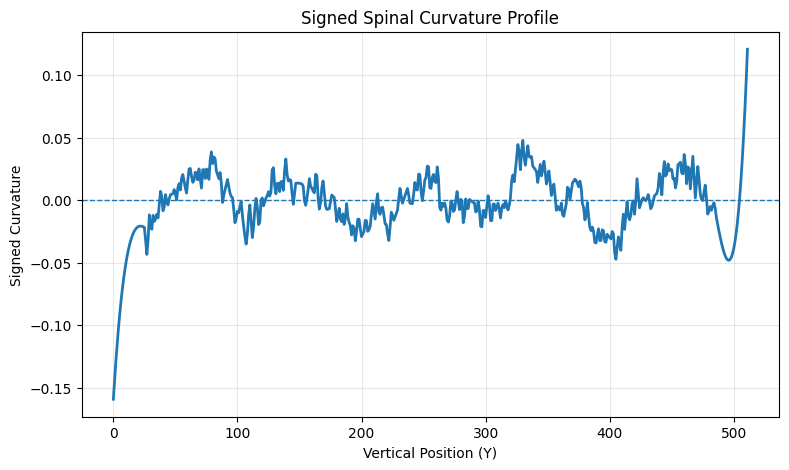

In [ ]:
# Analyze signed spinal curvature

x = centerline[:, 0]
y = centerline[:, 1]

# First derivative = spinal slope
dx = np.gradient(x)

# Second derivative = change in slope
d2x_signed = np.gradient(dx)

# Smooth signed curvature
signed_curvature = savgol_filter(
    d2x_signed,
    51,
    3
)

# Plot signed curvature
plt.figure(figsize=(9, 5))

plt.plot(
    y,
    signed_curvature,
    linewidth=2
)

# Zero reference line
plt.axhline(
    0,
    linewidth=1,
    linestyle="--"
)

plt.xlabel("Vertical Position (Y)")
plt.ylabel("Signed Curvature")
plt.title("Signed Spinal Curvature Profile")

plt.grid(alpha=0.3)
plt.show()

In [ ]:
from scipy.signal import find_peaks, savgol_filter
import cv2
import numpy as np


def calculate_local_cobb_angles(image_path):


    image = cv2.imread(image_path)

    if image is None:
        return []

    gray = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)


    clahe = cv2.createCLAHE(
        clipLimit=2.0,
        tileGridSize=(8, 8)
    )

    enhanced = clahe.apply(gray)


    h, w = enhanced.shape

    x_start = int(w * 0.38)
    x_end = int(w * 0.68)

    spine_roi = enhanced[:, x_start:x_end]


    roi_smooth = cv2.GaussianBlur(
        spine_roi,
        (7, 7),
        0
    )

    h_roi, w_roi = roi_smooth.shape

    centerline = []

    x_prev = w_roi // 2
    window = 12

    for y in range(h_roi):

        row = roi_smooth[y]

        left = max(0, x_prev - window)
        right = min(w_roi, x_prev + window + 1)

        segment = row[left:right]

        if len(segment) > 0:
            x_local = np.argmax(segment)
            x = left + x_local
        else:
            x = x_prev

        centerline.append([x, y])
        x_prev = x

    centerline = np.array(centerline)


    centerline[:, 0] = savgol_filter(
        centerline[:, 0],
        101,
        3
    )


    x = centerline[:, 0]

    dx = np.gradient(x)
    d2x = np.gradient(dx)

    curvature = np.abs(d2x)

    curvature_smooth = savgol_filter(
        curvature,
        51,
        3
    )


    peaks, properties = find_peaks(
        curvature_smooth,
        distance=80,
        prominence=0.025
    )

    local_angles = []


    for peak in peaks:

        window_size = 60

        start_idx = max(
            0,
            peak - window_size
        )

        end_idx = min(
            len(centerline) - 1,
            peak + window_size
        )

        local_upper = centerline[start_idx:peak]
        local_lower = centerline[peak:end_idx]

        if len(local_upper) < 10 or len(local_lower) < 10:
            continue

        upper_part = local_upper[
            :int(len(local_upper) * 0.65)
        ]

        lower_part = local_lower[
            int(len(local_lower) * 0.35):
        ]

        if len(upper_part) < 5 or len(lower_part) < 5:
            continue

        m1, c1 = np.polyfit(
            upper_part[:, 1],
            upper_part[:, 0],
            1
        )

        m2, c2 = np.polyfit(
            lower_part[:, 1],
            lower_part[:, 0],
            1
        )

        theta = abs(
            np.arctan(m1) -
            np.arctan(m2)
        )

        angle = np.degrees(theta)

        if angle > 90:
            angle = 180 - angle

        local_angles.append(angle)

    return local_angles




print("=" * 75)
print("MULTI-PEAK COBB ANGLE EVALUATION")
print("=" * 75)

all_local_angles = []

for i in range(10):

    angles_detected = calculate_local_cobb_angles(
        train_images[i]
    )

    all_local_angles.append(
        angles_detected
    )

    gt = train_angles[i]

    print(f"\nImage {i+1:02d}")
    print(
        f"Ground Truth : "
        f"{gt[0]:.2f}°, "
        f"{gt[1]:.2f}°, "
        f"{gt[2]:.2f}°"
    )

    print(
        "Detected     : "
        + ", ".join(
            f"{a:.2f}°"
            for a in angles_detected
        )
    )

print("\n" + "=" * 75)

MULTI-PEAK COBB ANGLE EVALUATION

Image 01
Ground Truth : 0.00°, 8.13°, 14.18°
Detected     : 11.02°, 21.12°, 39.80°

Image 02
Ground Truth : 10.68°, 18.36°, 18.80°
Detected     : 31.01°, 43.40°, 5.84°, 25.46°

Image 03
Ground Truth : 11.22°, 25.58°, 7.72°
Detected     : 6.66°, 12.01°, 1.87°, 32.68°

Image 04
Ground Truth : 13.33°, 32.72°, 24.12°
Detected     : 6.79°, 31.67°, 12.08°, 0.46°

Image 05
Ground Truth : 10.58°, 21.59°, 18.37°
Detected     : 1.05°, 39.36°, 82.23°, 63.40°

Image 06
Ground Truth : 9.20°, 24.19°, 18.58°
Detected     : 69.30°, 41.30°, 47.92°, 3.12°, 24.97°, 53.53°

Image 07
Ground Truth : 4.44°, 9.45°, 3.50°
Detected     : 42.85°, 5.50°, 2.98°, 4.27°, 11.92°

Image 08
Ground Truth : 7.91°, 10.57°, 9.46°
Detected     : 0.89°, 30.81°, 15.22°, 23.54°

Image 09
Ground Truth : 0.00°, 10.01°, 15.36°
Detected     : 1.36°, 5.63°, 54.05°, 57.35°

Image 10
Ground Truth : 21.92°, 30.58°, 27.19°
Detected     : 9.13°, 22.34°, 30.26°, 21.12°



In [ ]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.multioutput import MultiOutputRegressor

# Create Random Forest regressor
rf = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    n_jobs=-1,
    max_depth=None
)

# Multi-output regression for 3 Cobb angles
cobb_model = MultiOutputRegressor(rf)

# Train
cobb_model.fit(
    train_pca,
    train_angles
)

print("Cobb-angle regression model trained successfully!")

Cobb-angle regression model trained successfully!


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Predict 3 Cobb angles for validation images
val_predictions = cobb_model.predict(val_pca)

print("Prediction shape:", val_predictions.shape)

# Calculate MAE for each angle
mae_angle1 = mean_absolute_error(
    val_angles[:, 0],
    val_predictions[:, 0]
)

mae_angle2 = mean_absolute_error(
    val_angles[:, 1],
    val_predictions[:, 1]
)

mae_angle3 = mean_absolute_error(
    val_angles[:, 2],
    val_predictions[:, 2]
)

# Overall MAE
overall_mae = mean_absolute_error(
    val_angles,
    val_predictions
)

# RMSE
overall_rmse = np.sqrt(
    mean_squared_error(
        val_angles,
        val_predictions
    )
)

print("\n" + "=" * 50)
print("COBB ANGLE REGRESSION RESULTS")
print("=" * 50)

print(f"Angle 1 MAE : {mae_angle1:.2f}°")
print(f"Angle 2 MAE : {mae_angle2:.2f}°")
print(f"Angle 3 MAE : {mae_angle3:.2f}°")

print("-" * 50)

print(f"Overall MAE : {overall_mae:.2f}°")
print(f"Overall RMSE: {overall_rmse:.2f}°")

print("=" * 50)

Prediction shape: (200, 3)

COBB ANGLE REGRESSION RESULTS
Angle 1 MAE : 5.00°
Angle 2 MAE : 6.22°
Angle 3 MAE : 6.62°
--------------------------------------------------
Overall MAE : 5.95°
Overall RMSE: 8.20°


In [ ]:
from sklearn.neural_network import MLPRegressor
from sklearn.multioutput import MultiOutputRegressor


mlp = MLPRegressor(
    hidden_layer_sizes=(128, 64),
    activation="relu",
    solver="adam",
    learning_rate_init=0.001,
    max_iter=500,
    random_state=42,
    early_stopping=True,
    validation_fraction=0.15,
    n_iter_no_change=30
)

mlp.fit(
    train_pca,
    train_angles
)

print("MLP Cobb-angle regression model trained successfully!")
print("Training iterations:", mlp.n_iter_)

MLP Cobb-angle regression model trained successfully!
Training iterations: 59


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np


val_pred_mlp = mlp.predict(val_pca)

mae_angle1 = mean_absolute_error(val_angles[:, 0], val_pred_mlp[:, 0])
mae_angle2 = mean_absolute_error(val_angles[:, 1], val_pred_mlp[:, 1])
mae_angle3 = mean_absolute_error(val_angles[:, 2], val_pred_mlp[:, 2])

overall_mae = mean_absolute_error(val_angles, val_pred_mlp)
overall_rmse = np.sqrt(mean_squared_error(val_angles, val_pred_mlp))

print("MLP Cobb Angle Results")
print("-" * 40)
print(f"Angle 1 MAE : {mae_angle1:.2f}°")
print(f"Angle 2 MAE : {mae_angle2:.2f}°")
print(f"Angle 3 MAE : {mae_angle3:.2f}°")
print(f"Overall MAE : {overall_mae:.2f}°")
print(f"Overall RMSE: {overall_rmse:.2f}°")

MLP Cobb Angle Results
----------------------------------------
Angle 1 MAE : 5.01°
Angle 2 MAE : 5.31°
Angle 3 MAE : 6.64°
Overall MAE : 5.65°
Overall RMSE: 7.51°


In [ ]:


for i in range(10):
    print(f"Image {i+1}")
    print(f"  Ground Truth : {val_angles[i]}")
    print(f"  MLP Predicted: {np.round(val_pred_mlp[i], 2)}")
    print()

Image 1
  Ground Truth : [          0        4.97        6.32]
  MLP Predicted: [       1.25       12.88       14.26]

Image 2
  Ground Truth : [      12.62       17.81       25.91]
  MLP Predicted: [       2.31        8.97       10.47]

Image 3
  Ground Truth : [      11.54       19.43        9.02]
  MLP Predicted: [       7.73       17.18        10.4]

Image 4
  Ground Truth : [       4.77       18.11       21.68]
  MLP Predicted: [       6.29       14.26       12.41]

Image 5
  Ground Truth : [        1.7       10.44       24.46]
  MLP Predicted: [       8.75       24.24       18.38]

Image 6
  Ground Truth : [      19.05       24.94          24]
  MLP Predicted: [       6.02       16.52       18.45]

Image 7
  Ground Truth : [      21.52       59.32       34.74]
  MLP Predicted: [      30.27        55.2       35.27]

Image 8
  Ground Truth : [      11.81       18.86       13.63]
  MLP Predicted: [       5.76       16.85       17.33]

Image 9
  Ground Truth : [       4.95       13.6

In [ ]:
# Absolute error for every validation sample and every angle

absolute_errors = np.abs(val_angles - val_pred_mlp)

print("Mean Absolute Error per angle:")
print(f"Angle 1: {absolute_errors[:, 0].mean():.2f}°")
print(f"Angle 2: {absolute_errors[:, 1].mean():.2f}°")
print(f"Angle 3: {absolute_errors[:, 2].mean():.2f}°")

print("\nMaximum error:")
print(f"Angle 1: {absolute_errors[:, 0].max():.2f}°")
print(f"Angle 2: {absolute_errors[:, 1].max():.2f}°")
print(f"Angle 3: {absolute_errors[:, 2].max():.2f}°")

print("\nSamples with any error > 15°:")
print(np.sum(np.any(absolute_errors > 15, axis=1)))

Mean Absolute Error per angle:
Angle 1: 5.01°
Angle 2: 5.31°
Angle 3: 6.64°

Maximum error:
Angle 1: 24.18°
Angle 2: 25.99°
Angle 3: 49.20°

Samples with any error > 15°:
20


In [ ]:
import os
import joblib

# Existing project folder
model_dir = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

os.makedirs(model_dir, exist_ok=True)

mlp_path = os.path.join(model_dir, "cobb_mlp_regressor.pkl")

joblib.dump(mlp, mlp_path)

print("MLP Cobb-angle model saved successfully!")
print("Path:", mlp_path)

MLP Cobb-angle model saved successfully!
Path: /content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/cobb_mlp_regressor.pkl


In [ ]:
from sklearn.preprocessing import StandardScaler


scaler = StandardScaler()

train_features_scaled = scaler.fit_transform(train_features)
val_features_scaled = scaler.transform(val_features)

print("StandardScaler recreated successfully!")
print("Train:", train_features_scaled.shape)
print("Validation:", val_features_scaled.shape)

StandardScaler recreated successfully!
Train: (800, 1280)
Validation: (200, 1280)


In [ ]:
from sklearn.decomposition import PCA

pca = PCA(n_components=64, random_state=42)

train_pca = pca.fit_transform(train_features_scaled)
val_pca = pca.transform(val_features_scaled)

print("PCA-64 recreated successfully!")
print("Train PCA shape:", train_pca.shape)
print("Validation PCA shape:", val_pca.shape)
print(f"Explained variance: {pca.explained_variance_ratio_.sum() * 100:.2f}%")

PCA-64 recreated successfully!
Train PCA shape: (800, 64)
Validation PCA shape: (200, 64)
Explained variance: 62.18%


In [ ]:
import os
import joblib

model_dir = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

scaler_path = os.path.join(model_dir, "cobb_standard_scaler.pkl")
pca_path = os.path.join(model_dir, "cobb_pca_64.pkl")

joblib.dump(scaler, scaler_path)
joblib.dump(pca, pca_path)

print("Cobb-angle preprocessing saved successfully!")
print()
print("Scaler:", scaler_path)
print("PCA   :", pca_path)

Cobb-angle preprocessing saved successfully!

Scaler: /content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/cobb_standard_scaler.pkl
PCA   : /content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/cobb_pca_64.pkl


In [ ]:
import os
import joblib

model_dir = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

files_to_check = [
    "cobb_mlp_regressor.pkl",
    "cobb_standard_scaler.pkl",
    "cobb_pca_64.pkl"
]

print("Checking saved Cobb-angle files...\n")

for filename in files_to_check:
    path = os.path.join(model_dir, filename)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {filename}  |  {size_mb:.2f} MB")
    else:
        print(f"✗ {filename}  |  NOT FOUND")

mlp_test = joblib.load(
    os.path.join(model_dir, "cobb_mlp_regressor.pkl")
)

scaler_test = joblib.load(
    os.path.join(model_dir, "cobb_standard_scaler.pkl")
)

pca_test = joblib.load(
    os.path.join(model_dir, "cobb_pca_64.pkl")
)

print("\nAll three files loaded successfully!")
print("MLP output dimensions:", mlp_test.n_outputs_)
print("PCA components:", pca_test.n_components_)

Checking saved Cobb-angle files...

✓ cobb_mlp_regressor.pkl  |  0.20 MB
✓ cobb_standard_scaler.pkl  |  0.03 MB
✓ cobb_pca_64.pkl  |  0.32 MB

All three files loaded successfully!
MLP output dimensions: 3
PCA components: 64


In [ ]:
import cv2
import numpy as np
from tensorflow.keras.applications.mobilenet_v2 import preprocess_input


test_index = 0
test_image_path = val_images[test_index]


test_image = cv2.imread(test_image_path)


test_image = cv2.cvtColor(test_image, cv2.COLOR_BGR2RGB)


test_image = cv2.resize(test_image, (224, 224))

true_angles = val_angles[test_index]

print("Image loaded successfully!")
print("Image path:", test_image_path)
print("Image shape:", test_image.shape)
print("Ground truth:", np.round(true_angles, 2))

Image loaded successfully!
Image path: /content/spinal_ai_sample/Spinal-AI2024-main/Spinal-AI2024-subset1/000522.jpg
Image shape: (224, 224, 3)
Ground truth: [          0        4.97        6.32]


In [ ]:

image_batch = np.expand_dims(test_image, axis=0)
image_batch = preprocess_input(image_batch.astype(np.float32))


features = feature_extractor.predict(image_batch, verbose=0)

features_scaled = scaler_test.transform(features)

features_pca = pca_test.transform(features_scaled)

predicted_angles = mlp_test.predict(features_pca)[0]


errors = np.abs(true_angles - predicted_angles)

print("Complete Cobb-angle inference test")
print("=" * 45)

print("MobileNetV2 features :", features.shape)
print("PCA features        :", features_pca.shape)

print("\nGround Truth:")
print(np.round(true_angles, 2))

print("\nPredicted:")
print(np.round(predicted_angles, 2))

print("\nAbsolute Error:")
print(np.round(errors, 2))

Complete Cobb-angle inference test
MobileNetV2 features : (1, 1280)
PCA features        : (1, 64)

Ground Truth:
[          0        4.97        6.32]

Predicted:
[       1.41       12.77       14.08]

Absolute Error:
[       1.41         7.8        7.76]


In [ ]:
import os

model_dir = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

feature_extractor_path = os.path.join(
    model_dir,
    "cobb_mobilenetv2_feature_extractor.keras"
)

feature_extractor.save(feature_extractor_path)

print("Cobb MobileNetV2 feature extractor saved successfully!")
print("Path:", feature_extractor_path)

Cobb MobileNetV2 feature extractor saved successfully!
Path: /content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model/cobb_mobilenetv2_feature_extractor.keras


In [ ]:
import os

model_dir = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

cobb_files = [
    "cobb_mobilenetv2_feature_extractor.keras",
    "cobb_standard_scaler.pkl",
    "cobb_pca_64.pkl",
    "cobb_mlp_regressor.pkl"
]

print("Cobb-angle deployment package")
print("=" * 50)

all_found = True

for filename in cobb_files:
    path = os.path.join(model_dir, filename)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✓ {filename:<45} {size_mb:.2f} MB")
    else:
        print(f"✗ {filename:<45} NOT FOUND")
        all_found = False

print()

if all_found:
    print("✓ All Cobb-angle deployment files are ready!")
else:
    print("⚠ Some files are missing.")

Cobb-angle deployment package
✓ cobb_mobilenetv2_feature_extractor.keras      9.16 MB
✓ cobb_standard_scaler.pkl                      0.03 MB
✓ cobb_pca_64.pkl                               0.32 MB
✓ cobb_mlp_regressor.pkl                        0.20 MB

✓ All Cobb-angle deployment files are ready!


In [ ]:
import shutil
import os

source_dir = "/content/drive/MyDrive/Scoliosis_Project 1/hybrid_qml_model"

cobb_files = [
    "cobb_mobilenetv2_feature_extractor.keras",
    "cobb_standard_scaler.pkl",
    "cobb_pca_64.pkl",
    "cobb_mlp_regressor.pkl"
]

temp_dir = "/content/cobb_deployment_files"
os.makedirs(temp_dir, exist_ok=True)

for filename in cobb_files:
    shutil.copy(
        os.path.join(source_dir, filename),
        os.path.join(temp_dir, filename)
    )


zip_path = "/content/cobb_deployment_files.zip"
shutil.make_archive(
    "/content/cobb_deployment_files",
    "zip",
    temp_dir
)

print("ZIP created successfully!")
print(zip_path)

ZIP created successfully!
/content/cobb_deployment_files.zip


In [ ]:
from google.colab import files

files.download("/content/cobb_deployment_files.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>